# 15 · Perfect-supplier replenishment: JEPA planner vs tuned textbook rules

The world has one shop, four products, and one perfect supplier: what the shop pays for arrives in full after the delivery lag. Only demand is uncertain, and the shop sees sales, not demand (ADR 0033, `src/perfect_supplier/README.md`).

**Arms.** Every arm runs closed-loop on its own copy of each eval world, with the same demand path. Comparisons are therefore paired world by world.

| arm | what it is |
| --- | --- |
| `jepa` | planner + JEPA quantile forecaster (the learned buyer) |
| `direct` | planner + the same network without the JEPA latent loss (ablation) |
| `planner_moving_average` | planner + 28-day moving-average normal forecast (no learning) |
| `planner_oracle` | planner + the true expected demand path and CV (ceiling; not a real policy) |
| `tuned_*` | the four textbook rules, each tuned **once** across 64 tune worlds |
| `default_order_up_to` | the engine's default (s,S) |
| `never_order` | floor |

**Score** is margin capture: Δequity / ((price − cost) × total demand). 1.0 means every demanded unit was sold with no fee and no holding cost.

Data lives under `ROOT`. Run the commands in the README first if it is empty.

In [1]:
%matplotlib inline
import json
import sys
from pathlib import Path

REPO = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(REPO))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.perfect_supplier import data, analysis
from src.perfect_supplier.analysis import LABELS

ROOT = REPO / "runs" / "perfect-supplier"
pd.set_option("display.width", 200, "display.max_columns", 60)

## 1 · The summary frame

One row per (world, arm). It holds the world's parameters (`delivery_lag`, `holding_rate`, `cv`, `weekly_amp`, `capacity`, `initial_cash`), per-product `base_mean_p*` and `initial_on_hand_p*`, realised `mean_demand_p*`, `zero_demand_days_p*`, `mean_order_qty_p*`, `order_count_p*`, and `fill_rate_p*`. It also holds the outcome: `score`, `delta_equity`, `net_profit`, `revenue`, `fees`, `holding_cost`, `lost_units`, and `order_days`. `split` is `train` (behaviour log), `eval` (final comparison), or `shadow`.

In [2]:
summary = data.load_summary(ROOT)
print(summary.groupby(["split", "method"]).size().rename("worlds").to_string())
summary.head(3).T

split   method                    
eval    default_order_up_to            500
        direct                         500
        jepa                           500
        never_order                    500
        planner_moving_average         500
        planner_oracle                 500
        tuned_order_up_to              500
        tuned_periodic_order_up_to     500
        tuned_periodic_reorder         500
        tuned_reorder_point            500
shadow  jepa                            12
train   behavior                      2000


,0,1,2
method,default_order_up_to,default_order_up_to,default_order_up_to
world_seed,3000000,3000001,3000002
split,eval,eval,eval
n_days,365,365,365
delivery_lag,7,5,6
...,...,...,...
order_count_p3,25,22,22
fill_rate_p3,1.0,0.997375,0.994245
mean_on_hand_p3,35.4,164.482192,84.654795
behavior,default_order_up_to,default_order_up_to,default_order_up_to


## 2 · Headline: paired comparison on the eval worlds

The baseline is the best tuned textbook rule by mean score. `diff_vs_baseline` is the mean world-by-world difference in score, with a 95% bootstrap interval. `win_rate` is the share of worlds where the arm beats the baseline.

In [3]:
ev = summary[summary["split"] == "eval"]
tuned = [m for m in ev["method"].unique() if m.startswith("tuned_")]
BASELINE = ev[ev["method"].isin(tuned)].groupby("method")["score"].mean().idxmax()
print("baseline:", BASELINE)
table = analysis.paired_table(summary, BASELINE)
(table.assign(**{c: table[c] * 100 for c in ["diff_vs_baseline", "ci_low", "ci_high"]})
      .rename(columns={"diff_vs_baseline": "diff (pts)", "ci_low": "ci low (pts)", "ci_high": "ci high (pts)"})
      .round(3))

baseline: tuned_periodic_order_up_to


,mean_score,diff (pts),ci low (pts),ci high (pts),win_rate,n_worlds
arm,,,,,,
planner_oracle,0.963,2.801,2.731,2.870,1.000,500
jepa,0.959,2.427,2.363,2.492,1.000,500
direct,0.959,2.426,2.360,2.492,1.000,500
planner_moving_average,0.956,2.072,2.000,2.142,1.000,500
tuned_periodic_order_up_to,0.935,0.000,0.000,0.000,0.000,500
tuned_reorder_point,0.929,-0.586,-0.692,-0.480,0.422,500
tuned_periodic_reorder,0.929,-0.609,-0.746,-0.475,0.492,500
tuned_order_up_to,0.929,-0.611,-0.734,-0.493,0.456,500
default_order_up_to,0.927,-0.822,-0.980,-0.667,0.438,500


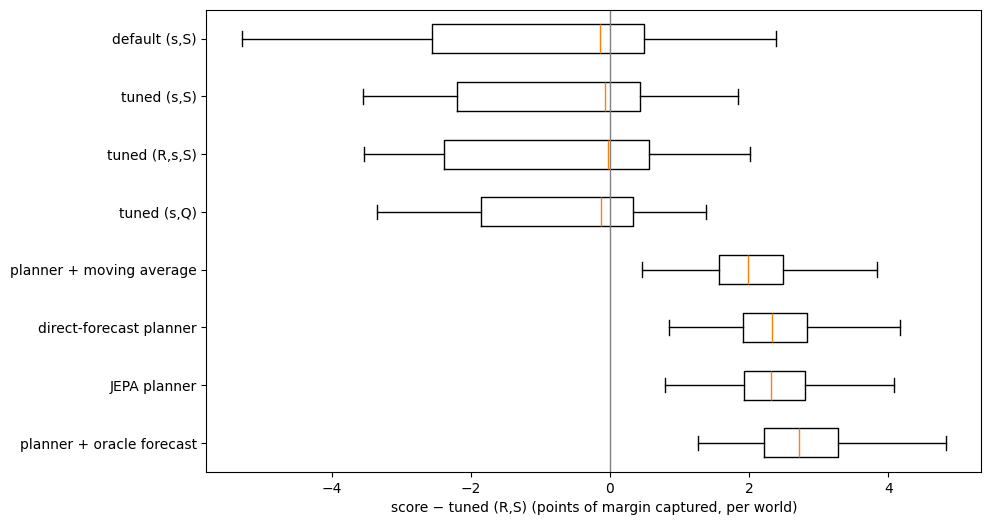

In [4]:
fig, ax = plt.subplots(figsize=(10, 6))
analysis.plot_paired(summary, BASELINE, arms=[a for a in table.index if a != "never_order"], ax=ax);

Pairwise against **every** tuned textbook rule, and JEPA against its own ablations. The planner + moving-average arm separates the planner's value from the forecast's value.

In [5]:
m = analysis.score_matrix(summary).dropna()
rows = []
for a, b in [("jepa", t) for t in tuned] + [("jepa", "direct"), ("jepa", "planner_moving_average"), ("planner_oracle", "jepa")]:
    d = (m[a] - m[b]).to_numpy()
    lo, hi = analysis.bootstrap_ci(d)
    rows.append({"arm": a, "vs": b, "diff (pts)": d.mean() * 100, "ci low": lo * 100, "ci high": hi * 100, "win rate": (d > 0).mean()})
pd.DataFrame(rows).round(3)

,arm,vs,diff (pts),ci low,ci high,win rate
0,jepa,tuned_order_up_to,3.038,2.912,3.163,1.000
1,jepa,tuned_periodic_order_up_to,2.427,2.363,2.492,1.000
2,jepa,tuned_periodic_reorder,3.036,2.897,3.175,1.000
3,jepa,tuned_reorder_point,3.013,2.900,3.128,1.000
4,jepa,direct,0.002,-0.013,0.016,0.514
5,jepa,planner_moving_average,0.355,0.324,0.387,0.906
6,planner_oracle,jepa,0.374,0.346,0.402,0.990


## 3 · Where the margin goes

Each arm's lost margin is split into lost sales, order fees, and holding cost, each as a share of the margin on all demand.

In [6]:
analysis.breakdown(summary).round(4)

,score,lost_sales,fees_share,holding_share,order_days,fill_rate_demand,mean_on_hand
method,,,,,,,
planner_oracle,0.9629,0.0032,0.0141,0.0198,47.274,0.9968,73.5654
jepa,0.9592,0.0049,0.0148,0.0211,49.390,0.9951,78.3696
direct,0.9592,0.0049,0.0148,0.0210,49.570,0.9951,78.2213
planner_moving_average,0.9556,0.0083,0.0150,0.0210,50.068,0.9917,79.1816
tuned_periodic_order_up_to,0.9349,0.0133,0.0284,0.0234,91.000,0.9867,63.9025
tuned_reorder_point,0.9291,0.0056,0.0293,0.0361,94.414,0.9944,98.4032
tuned_periodic_reorder,0.9288,0.0048,0.0269,0.0395,86.870,0.9952,107.4907
tuned_order_up_to,0.9288,0.0052,0.0281,0.0379,90.642,0.9948,103.1565
default_order_up_to,0.9267,0.0055,0.0263,0.0415,85.310,0.9945,112.3442


## 4 · Which worlds the learned buyer wins

Mean paired difference to the baseline, cut by world parameters.

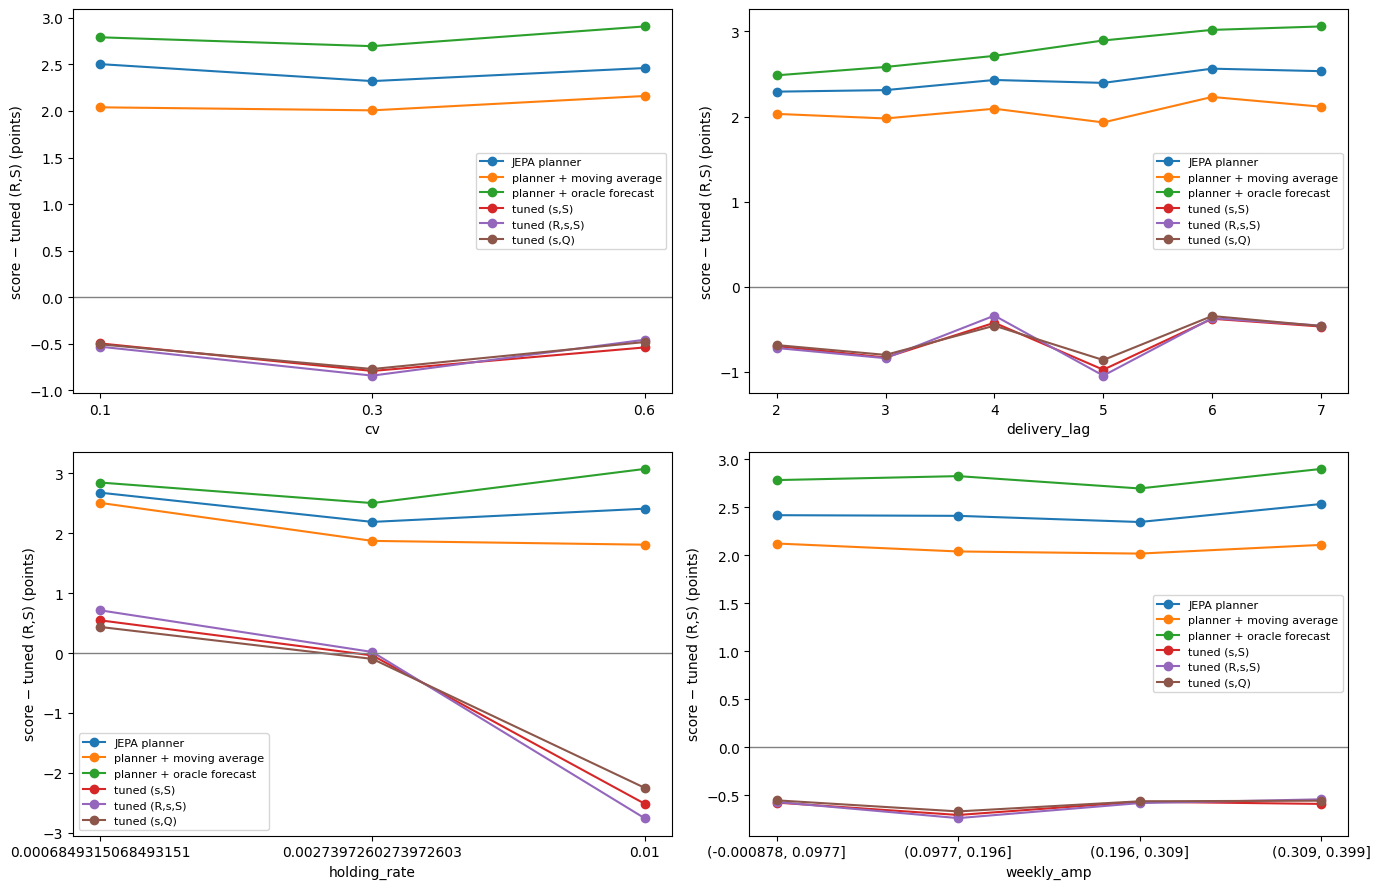

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
arms = ["jepa", "planner_moving_average", "planner_oracle"] + [t for t in tuned if t != BASELINE]
for ax, feat in zip(axes.flat, ["cv", "delivery_lag", "holding_rate", "weekly_amp"]):
    analysis.plot_by_world_feature(summary, BASELINE, feat, arms, ax=ax)
fig.tight_layout()

## 5 · The forecaster

Training curves from `models/*_fit.json`. `pinball` is the censored loss on held-out **sales** (what the model trains on). `pinball_true_demand` is scored against true demand, which the model never sees. That number is inflated by stretches where a behaviour policy left the shelf empty for weeks: demand there cannot be identified from sales by any forecaster.

,step,pinball,pinball_true_demand,coverage
9,20000,0.089285,0.407049,"[0.025631427764892578, 0.09595143049955368, 0...."


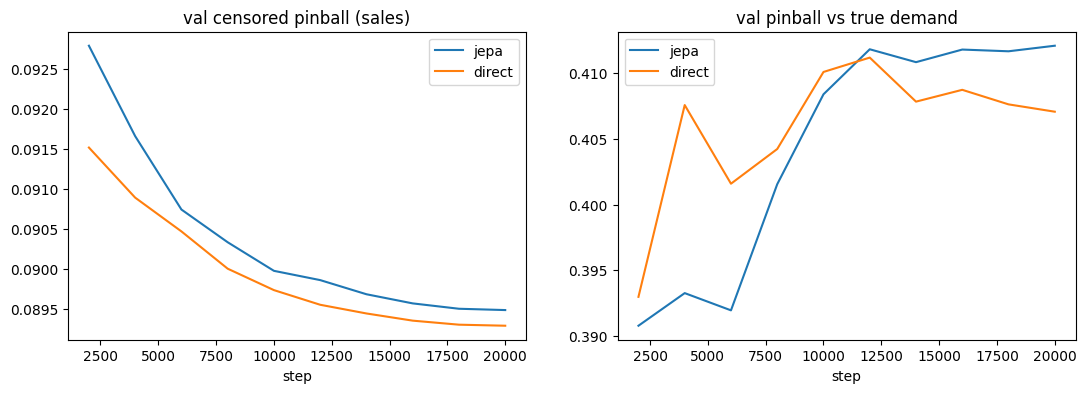

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for arm in ["jepa", "direct"]:
    path = ROOT / "models" / f"{arm}_fit.json"
    if not path.exists():
        continue
    h = pd.DataFrame(json.loads(path.read_text())["history"])
    ax[0].plot(h["step"], h["pinball"], label=arm)
    ax[1].plot(h["step"], h["pinball_true_demand"], label=arm)
ax[0].set_title("val censored pinball (sales)"); ax[1].set_title("val pinball vs true demand")
for a in ax: a.legend(); a.set_xlabel("step")
h.iloc[-1:][["step", "pinball", "pinball_true_demand", "coverage"]]

## 6 · One world, every arm on its own run

Change `SEED`, `PRODUCT`, `ARMS`, and `DAYS`. By default the seed is the world where JEPA loses most to the baseline. Look there first for illogical decisions.

In [9]:
diff = (m["jepa"] - m[BASELINE]).sort_values()
print("JEPA worst worlds:\n", (diff.head(5) * 100).round(2).to_string())
print("JEPA best worlds:\n", (diff.tail(5) * 100).round(2).to_string())
SEED = int(diff.index[0])
PRODUCT = 0
ARMS = ["jepa", BASELINE, "planner_oracle"]
DAYS = (0, 120)
ts = data.load_timeseries(ROOT, split="eval", method=ARMS, world_seed=SEED)
ev[ev["world_seed"] == SEED].set_index("method")[["score", "order_days", "fees", "holding_cost", "lost_units", "delivery_lag", "cv", "holding_rate"]].loc[ARMS]

JEPA worst worlds:
 world_seed
3000425    0.55
3000093    0.78
3000251    0.92
3000106    0.99
3000271    1.14
JEPA best worlds:
 world_seed
3000346    4.84
3000193    4.85
3000319    4.86
3000092    4.96
3000434    5.53


,score,order_days,fees,holding_cost,lost_units,delivery_lag,cv,holding_rate
method,,,,,,,,
jepa,0.901064,73,3650.0,9038.9,229,6,0.6,0.01
tuned_periodic_order_up_to,0.895554,91,4550.0,9323.2,194,6,0.6,0.01
planner_oracle,0.914508,68,3400.0,8583.5,96,6,0.6,0.01


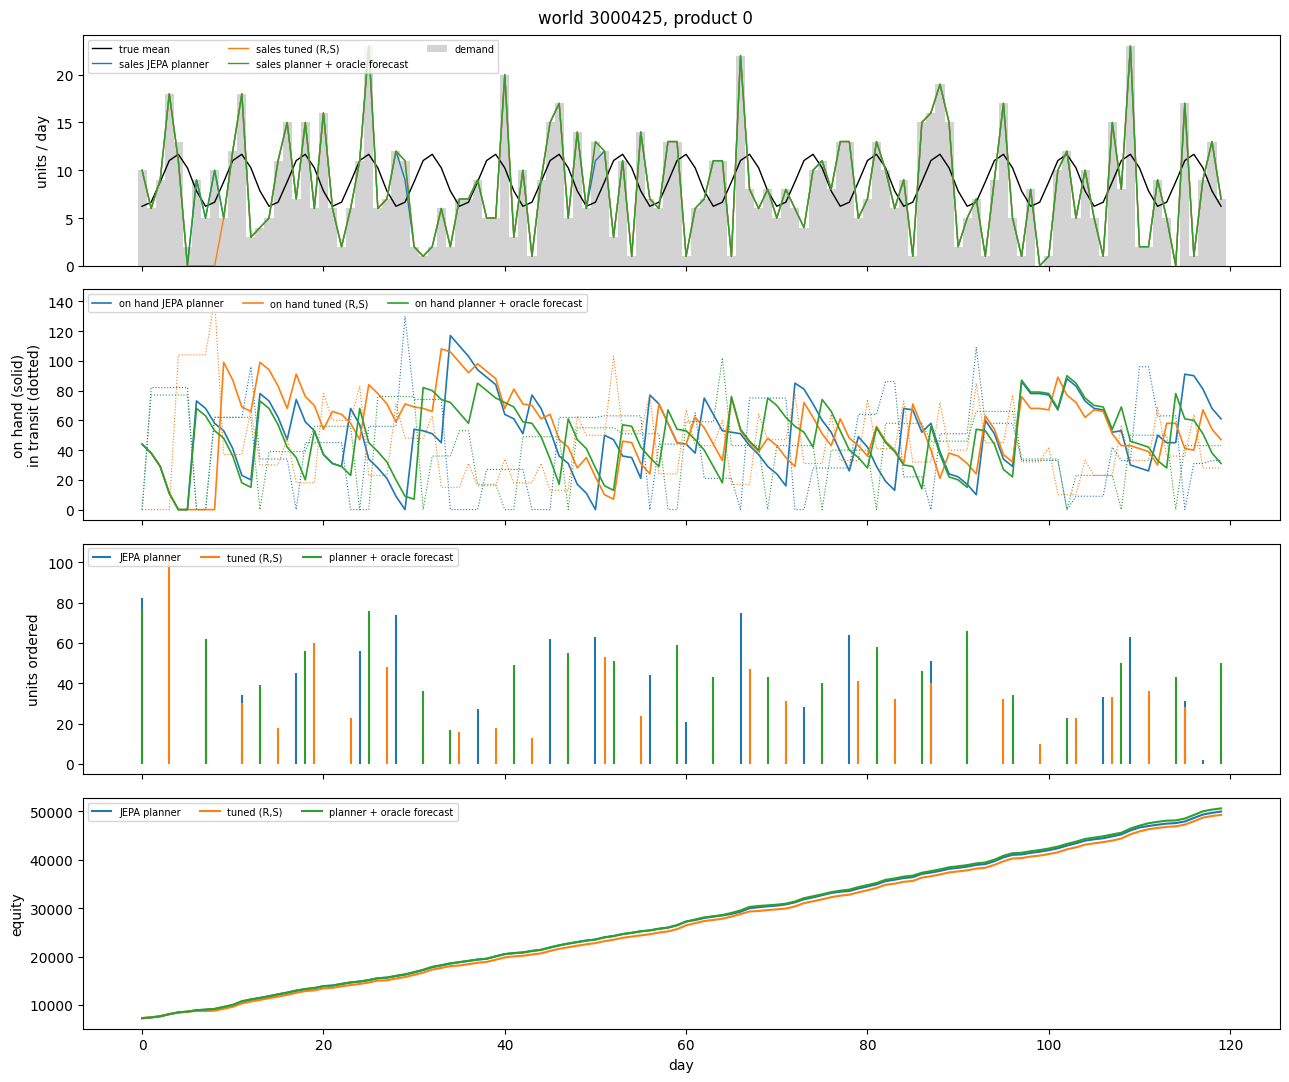

In [10]:
analysis.plot_world(ts, SEED, PRODUCT, ARMS, days=DAYS);

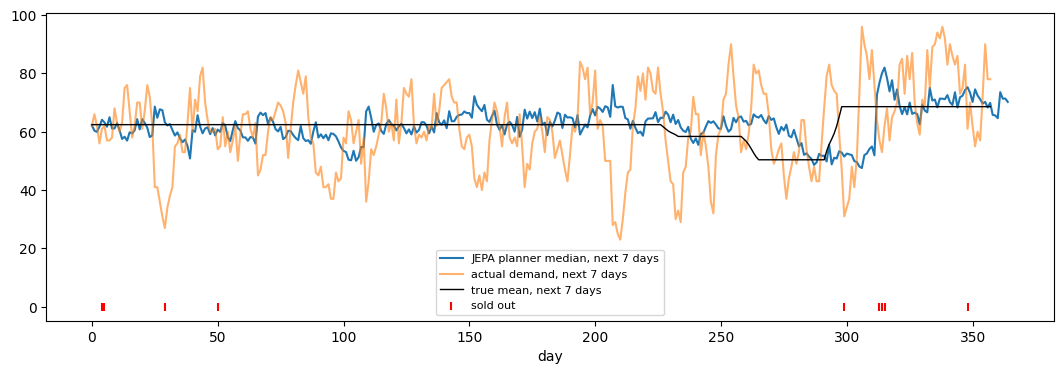

In [11]:
analysis.plot_forecast(ts, SEED, PRODUCT, "jepa");

The JEPA arm's decision columns (`dec_*`) per day:
- `dec_review`, `dec_service`: the winning plan
- `dec_order_today`: whether that plan orders today
- `dec_score`: its imagined Δequity over 35 days
- `dec_score_best_wait`, `dec_score_best_order`: the best plan that waits vs the best that orders
- `dec_forecast_mean_7d`: the median forecast summed over the next 7 days

In [12]:
cols = ["day", "product", "demand", "sales", "on_hand_close", "in_transit", "requested", "filled",
        "dec_review", "dec_service", "dec_order_today", "dec_score", "dec_score_best_wait", "dec_score_best_order", "dec_forecast_mean_7d"]
ts[(ts["method"] == "jepa") & (ts["product"] == PRODUCT)][cols].head(30)

,day,product,demand,sales,on_hand_close,in_transit,requested,filled,dec_review,dec_service,dec_order_today,dec_score,dec_score_best_wait,dec_score_best_order,dec_forecast_mean_7d
0,0,0,10,10,44,0,82,82,7.0,0.8,True,11272.181250,NaN,11272.181250,62.209328
4,1,0,6,6,38,82,0,0,7.0,0.8,False,11441.942188,11441.942188,NaN,60.347626
8,2,0,9,9,29,82,0,0,7.0,0.7,False,11320.904688,11320.904688,NaN,59.940384
12,3,0,18,18,11,82,0,0,7.0,0.8,False,11196.162500,11196.162500,NaN,61.749584
16,4,0,13,11,0,82,0,0,7.0,0.8,False,11264.139063,11264.139063,11042.650000,64.097946
20,5,0,2,0,0,82,0,0,7.0,0.7,False,11150.154688,11150.154688,10980.957812,63.188034
24,6,0,9,9,73,0,0,0,7.0,0.8,False,10763.003125,10763.003125,10654.495313,61.718803
28,7,0,5,5,68,0,62,62,7.0,0.8,True,11064.193750,10975.579687,11064.193750,64.982170
32,8,0,10,10,58,62,0,0,7.0,0.8,False,10574.762500,10574.762500,NaN,61.114460
36,9,0,5,5,53,62,0,0,7.0,0.7,False,11006.787500,11006.787500,NaN,61.127293


## 7 · Shadow run: same state, every arm's decision

`split=shadow`: JEPA drives the shop. On every day the oracle planner, the moving-average planner, and the tuned textbook rules read the **same** observation, and what they would have requested is logged (`shadow_<arm>_requested`). Nothing they ask for is executed.

,planner_oracle,planner_moving_average,tuned_order_up_to,tuned_periodic_order_up_to,jepa (driver)
orders on same day (share of driver order days),0.88,0.79,0.62,0.23,1.00
mean units when ordering,88.16,89.04,186.64,51.04,88.36
order days per product-year,56.58,52.88,56.23,59.92,54.27


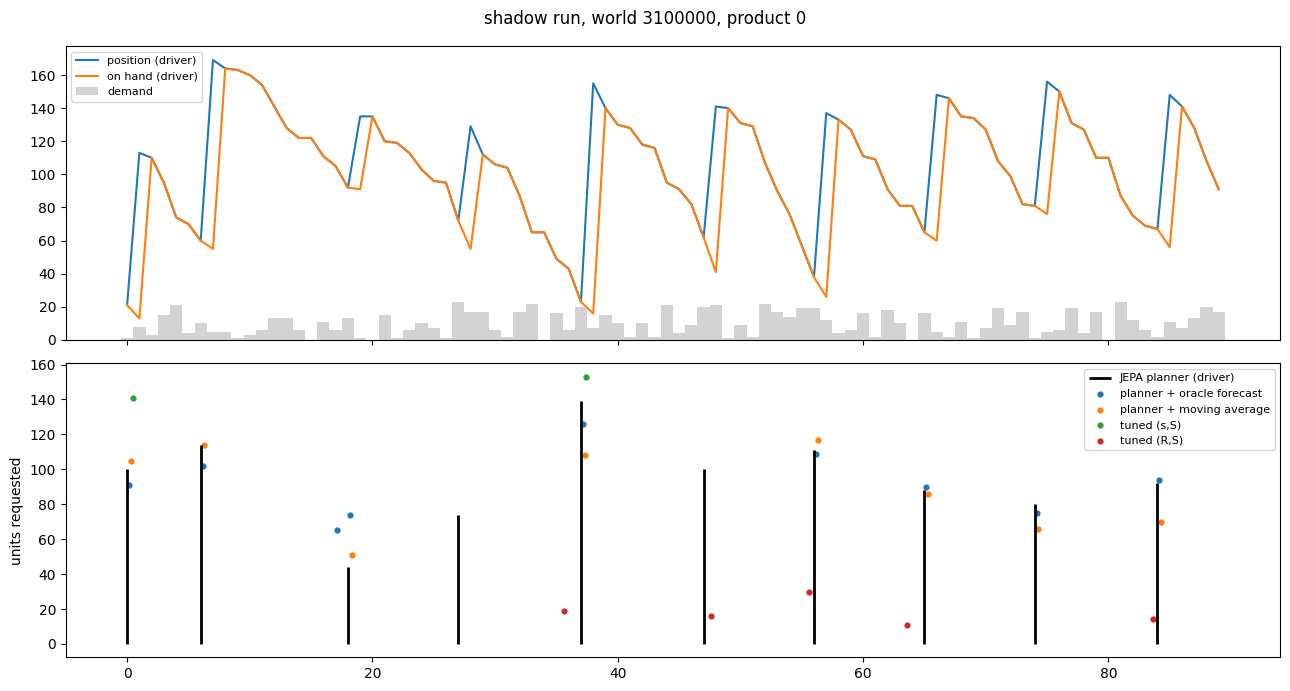

In [13]:
sh = data.load_timeseries(ROOT, split="shadow")
if len(sh):
    shadow_cols = [c for c in sh.columns if c.startswith("shadow_")]
    agree = pd.DataFrame({
        c.removeprefix("shadow_").removesuffix("_requested"): {
            "orders on same day (share of driver order days)": ((sh[c] > 0) & (sh["requested"] > 0)).sum() / max((sh["requested"] > 0).sum(), 1),
            "mean units when ordering": sh.loc[sh[c] > 0, c].mean(),
            "order days per product-year": (sh[c] > 0).groupby([sh["world_seed"], sh["product"]]).sum().mean(),
        } for c in shadow_cols})
    agree["jepa (driver)"] = [1.0, sh.loc[sh["requested"] > 0, "requested"].mean(), (sh["requested"] > 0).groupby([sh["world_seed"], sh["product"]]).sum().mean()]
    display(agree.round(2))
    analysis.plot_shadow(sh, int(sh["world_seed"].iloc[0]), 0, days=(0, 90))

## 8 · The detailed time-series frame

Every simulation is stored, training and evaluation alike: one row per day × product, partitioned by `split` and `method` under `timeseries/`. Read any slice without loading the rest:

```python
data.load_timeseries(ROOT, split="eval", method="jepa", world_seed=[3000000, 3000001])
data.load_timeseries(ROOT, split="train", columns=["world_seed", "day", "product", "demand", "sales", "censored"])
```

Columns:
- **Per product:** `demand`, `demand_mean` (truth, never shown to policies), `sales`, `lost`, `censored`, `on_hand_open`, `arrivals`, `in_transit`, `position`, `requested`, `filled`, `on_hand_close`
- **Shop, repeated on each product row:** `cash_open`, `cash_close`, `purchase_cost`, `fee_paid`, `revenue`, `holding_cost`, `equity_close`
- **Decisions:** `dec_*` for each arm's decision columns, `shadow_*` for shadow requests
- **Training log only:** `behavior` names the policy that ran the shop

In [14]:
print(sorted(p.name for p in (ROOT / "timeseries").glob("split=*/method=*")))
example = data.load_timeseries(ROOT, split="eval", method="jepa", world_seed=SEED)
print(example.shape)
example.head()

['method=behavior', 'method=default_order_up_to', 'method=direct', 'method=jepa', 'method=jepa', 'method=never_order', 'method=planner_moving_average', 'method=planner_oracle', 'method=tuned_order_up_to', 'method=tuned_periodic_order_up_to', 'method=tuned_periodic_reorder', 'method=tuned_reorder_point']
(1460, 33)


,world_seed,day,weekday,product,on_hand_open,arrivals,in_transit,position,requested,filled,demand,demand_mean,sales,lost,censored,on_hand_close,cash_open,cash_close,purchase_cost,fee_paid,revenue,holding_cost,equity_close,dec_review,dec_service,dec_order_today,dec_score,dec_score_best_wait,dec_score_best_order,dec_forecast_mean_7d,behavior,split,method
0,3000425,0,0,0,54,0,0,44,82,82,10,6.229558,10,0,False,44,4829.195089,2159.195089,3080.0,50.0,480.0,20.0,7239.195089,7,0.8,True,11272.181250,NaN,11272.18125,62.209328,jepa,eval,jepa
1,3000425,0,0,1,74,0,0,67,78,78,7,8.561485,7,0,False,67,4829.195089,2159.195089,3080.0,50.0,480.0,20.0,7239.195089,7,0.8,True,11272.181250,NaN,11272.18125,72.481453,jepa,eval,jepa
2,3000425,0,0,2,58,0,0,57,69,69,1,6.762633,1,0,False,57,4829.195089,2159.195089,3080.0,50.0,480.0,20.0,7239.195089,7,0.8,True,11272.181250,NaN,11272.18125,60.747959,jepa,eval,jepa
3,3000425,0,0,3,38,0,0,32,79,79,6,5.957501,6,0,False,32,4829.195089,2159.195089,3080.0,50.0,480.0,20.0,7239.195089,7,0.8,True,11272.181250,NaN,11272.18125,55.070782,jepa,eval,jepa
4,3000425,1,1,0,44,0,82,120,0,0,6,6.654069,6,0,False,38,2159.195089,2500.995089,0.0,0.0,360.0,18.2,7400.995089,7,0.8,False,11441.942188,11441.942188,NaN,60.347626,jepa,eval,jepa
